# Time Series Forecasting with Chronos-2 and OpenVINO™

Time series forecasting is at the heart of many business and engineering tasks: demand and capacity planning, energy load prediction, predictive maintenance, traffic and retail analytics. Traditionally, a separate statistical or deep learning model had to be trained for every dataset. **Time series foundation models** change this: pretrained on a huge collection of real and synthetic series, they produce accurate forecasts for previously unseen data *zero-shot*, without any training.

[Chronos-2](https://huggingface.co/amazon/chronos-2) is a time series foundation model with 120M parameters from Amazon. Unlike earlier Chronos and Chronos-Bolt models that support only univariate forecasting, Chronos-2 handles **univariate**, **multivariate** and **covariate-informed** forecasting tasks within a single architecture. The model is based on a T5-style encoder: the input series are split into patches, and the encoder alternates *time attention* (along the time axis of each series) with *group attention*, which exchanges information between related series within one task (for example, target series and their covariates). All forecast quantiles for the whole horizon are predicted in a single forward pass. At the time of release, Chronos-2 achieved state-of-the-art zero-shot accuracy on the [fev-bench](https://huggingface.co/spaces/autogluon/fev-leaderboard), [GIFT-Eval](https://huggingface.co/spaces/Salesforce/GIFT-Eval) and Chronos Benchmark II benchmarks.

In this tutorial, we consider how to convert Chronos-2 to OpenVINO™ Intermediate Representation (IR), compress its weights with [NNCF](https://github.com/openvinotoolkit/nncf) and use it as a drop-in replacement inside the original `Chronos2Pipeline` for forecasting of hourly bike sharing demand, with and without weather and calendar covariates.

More details about the model can be found in the [technical report](https://arxiv.org/abs/2510.15821), [model card](https://huggingface.co/amazon/chronos-2) and [GitHub repository](https://github.com/amazon-science/chronos-forecasting).

#### Table of contents:

- [Prerequisites](#Prerequisites)
- [Prepare the dataset](#Prepare-the-dataset)
- [Run the original PyTorch model](#Run-the-original-PyTorch-model)
- [Convert the model to OpenVINO IR](#Convert-the-model-to-OpenVINO-IR)
- [Compress model weights](#Compress-model-weights)
- [Select inference device](#Select-inference-device)
- [Run forecasting with OpenVINO](#Run-forecasting-with-OpenVINO)
    - [Univariate forecasting](#Univariate-forecasting)
    - [Forecasting with known future covariates](#Forecasting-with-known-future-covariates)
    - [Multivariate forecasting](#Multivariate-forecasting)
- [Compare accuracy and performance](#Compare-accuracy-and-performance)
- [Interactive demo](#Interactive-demo)
- [Clean up](#Clean-up)


### Installation Instructions

This is a self-contained example that relies solely on its own code.

We recommend  running the notebook in a virtual environment. You only need a Jupyter server to start.
For details, please refer to [Installation Guide](https://github.com/openvinotoolkit/openvino_notebooks/blob/latest/README.md#-installation-guide).

<img referrerpolicy="no-referrer-when-downgrade" src="https://static.scarf.sh/a.png?x-pxid=5b5a4db0-7875-4bfb-bdbd-01698b5b1a77&file=notebooks/chronos-2-time-series-forecasting/chronos-2-time-series-forecasting.ipynb" />


## Prerequisites
[back to top ⬆️](#Table-of-contents:)

Install the required packages. [`chronos-forecasting`](https://github.com/amazon-science/chronos-forecasting) package provides the original PyTorch model and `Chronos2Pipeline`, which takes care of data preparation (`pandas` data frames, grouping of targets and covariates, batching) and post-processing of model predictions.

In [1]:
from pathlib import Path

import requests

for helper_name in ("notebook_utils.py", "pip_helper.py"):
    helper_path = Path(helper_name)
    if not helper_path.exists():
        r = requests.get(url=f"https://raw.githubusercontent.com/openvinotoolkit/openvino_notebooks/latest/utils/{helper_name}")
        helper_path.write_text(r.text, encoding="utf-8")

from pip_helper import pip_install

pip_install("-q", "torch>=2.4", "--extra-index-url", "https://download.pytorch.org/whl/cpu")
pip_install("-q", "chronos-forecasting>=2.2,<3", "openvino>=2026.2", "nncf>=2.19", "pandas", "matplotlib", "ipywidgets", "gradio>=5.0")

# Read more about telemetry collection at https://github.com/openvinotoolkit/openvino_notebooks?tab=readme-ov-file#-telemetry
from notebook_utils import collect_telemetry

collect_telemetry("chronos-2-time-series-forecasting.ipynb")

## Prepare the dataset
[back to top ⬆️](#Table-of-contents:)

We will use the [Bike Sharing dataset](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset) from the UCI Machine Learning Repository (licensed under [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/)). It contains the hourly count of rented bikes in the Capital Bikeshare system (Washington, D.C.) in 2011-2012, split into `casual` and `registered` users, together with weather and calendar information:

* `temp` - normalized temperature, `hum` - normalized humidity, `windspeed` - normalized wind speed
* `weathersit` - weather situation (1: clear, 2: mist, 3: light rain or snow, 4: heavy rain or snow)
* `workingday`, `holiday` - calendar flags

> Fanaee-T, Hadi, and Gama, Joao, "Event labeling combining ensemble detectors and background knowledge", Progress in Artificial Intelligence (2013): pp. 1-15, Springer Berlin Heidelberg.

`Chronos2Pipeline` expects data in a *long* format: an id column identifying a series, a timestamp column with a regular frequency and one or more value columns. Several hours with no rentals are missing from the original data, so we restore the regular hourly grid, fill missing rental counts with zeros and propagate the last known weather values.

In [2]:
import zipfile

import pandas as pd

from notebook_utils import download_file

DATA_DIR = Path("data")
DATA_URL = "https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip"

if not (DATA_DIR / "hour.csv").exists():
    archive_path = download_file(url=DATA_URL, filename="bike_sharing_dataset.zip", directory=DATA_DIR)
    with zipfile.ZipFile(archive_path) as archive:
        archive.extract("hour.csv", DATA_DIR)

ID_COLUMN = "item_id"
TIMESTAMP_COLUMN = "timestamp"
TARGET = "cnt"
COVARIATES = ["temp", "hum", "windspeed", "weathersit", "workingday", "holiday"]

raw_df = pd.read_csv(DATA_DIR / "hour.csv")
raw_df[TIMESTAMP_COLUMN] = pd.to_datetime(raw_df["dteday"]) + pd.to_timedelta(raw_df["hr"], unit="h")
data = raw_df.set_index(TIMESTAMP_COLUMN).asfreq("h")
print(f"Restored {data[TARGET].isna().sum()} missing hours")
data[["cnt", "casual", "registered"]] = data[["cnt", "casual", "registered"]].fillna(0)
data = data.ffill().reset_index()
data[ID_COLUMN] = "bike_sharing"
data = data[[ID_COLUMN, TIMESTAMP_COLUMN, TARGET, "casual", "registered"] + COVARIATES]
data.tail()

Restored 165 missing hours


,item_id,timestamp,cnt,casual,registered,temp,hum,windspeed,weathersit,workingday,holiday
17539,bike_sharing,2012-12-31 19:00:00,119.0,11.0,108.0,0.26,0.60,0.1642,2.0,1.0,0.0
17540,bike_sharing,2012-12-31 20:00:00,89.0,8.0,81.0,0.26,0.60,0.1642,2.0,1.0,0.0
17541,bike_sharing,2012-12-31 21:00:00,90.0,7.0,83.0,0.26,0.60,0.1642,1.0,1.0,0.0
17542,bike_sharing,2012-12-31 22:00:00,61.0,13.0,48.0,0.26,0.56,0.1343,1.0,1.0,0.0
17543,bike_sharing,2012-12-31 23:00:00,49.0,12.0,37.0,0.26,0.65,0.1343,1.0,1.0,0.0


For the experiments below, we hide the last two weeks of the data and forecast the next 48 hours after this cut-off point, so the forecast can be compared with the ground truth. Let's look at the last weeks of the history. The series has a strong daily and weekly seasonality (commute peaks on working days), but its level depends on weather and holidays.

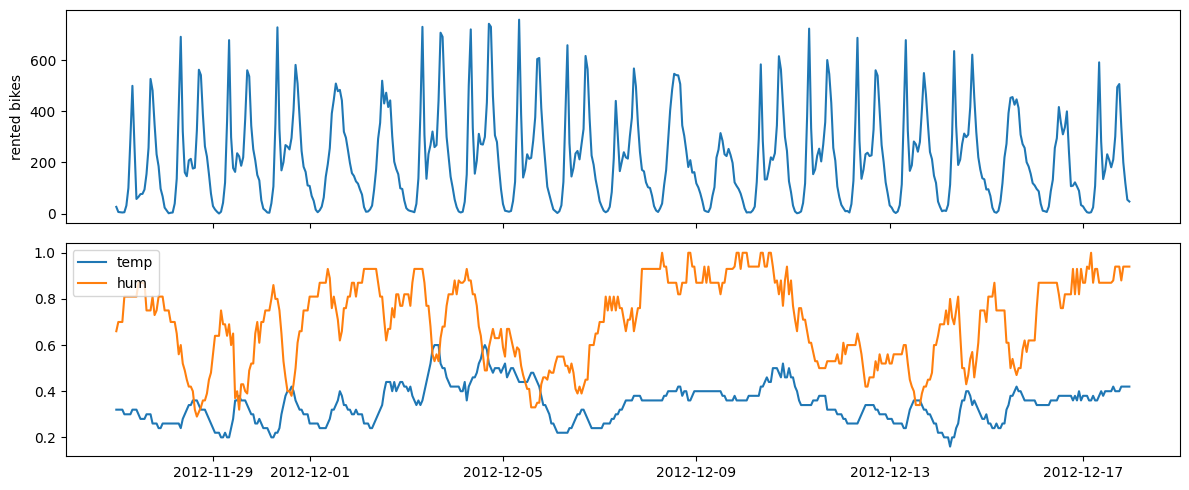

In [3]:
import matplotlib.pyplot as plt

PREDICTION_LENGTH = 48
CUTOFF = len(data) - 24 * 14

context_df = data.iloc[:CUTOFF]
future_df = data.iloc[CUTOFF : CUTOFF + PREDICTION_LENGTH]

history = context_df.tail(24 * 21)
fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
axes[0].plot(history[TIMESTAMP_COLUMN], history[TARGET])
axes[0].set_ylabel("rented bikes")
axes[1].plot(history[TIMESTAMP_COLUMN], history["temp"], label="temp")
axes[1].plot(history[TIMESTAMP_COLUMN], history["hum"], label="hum")
axes[1].legend(loc="upper left")
fig.tight_layout()

## Run the original PyTorch model
[back to top ⬆️](#Table-of-contents:)

`Chronos2Pipeline.from_pretrained` downloads the model from Hugging Face Hub. `predict_df` method accepts a data frame with historical values and returns a data frame with forecasts for requested quantile levels. The `predictions` column contains the median forecast.

We will keep the PyTorch result to compare it with OpenVINO later.

In [4]:
import time

import torch
from chronos import Chronos2Pipeline

MODEL_ID = "amazon/chronos-2"
QUANTILE_LEVELS = [0.1, 0.5, 0.9]

torch_pipeline = Chronos2Pipeline.from_pretrained(MODEL_ID, device_map="cpu", torch_dtype=torch.float32)

start = time.perf_counter()
torch_forecast_df = torch_pipeline.predict_df(
    context_df[[ID_COLUMN, TIMESTAMP_COLUMN, TARGET]],
    prediction_length=PREDICTION_LENGTH,
    quantile_levels=QUANTILE_LEVELS,
    id_column=ID_COLUMN,
    timestamp_column=TIMESTAMP_COLUMN,
    target=TARGET,
)
print(f"PyTorch forecast time: {time.perf_counter() - start:.2f} s")
torch_forecast_df.head()

PyTorch forecast time: 0.54 s


,item_id,timestamp,target_name,predictions,0.1,0.5,0.9
0,bike_sharing,2012-12-18 00:00:00,cnt,25.792511,13.801987,25.792511,37.412415
1,bike_sharing,2012-12-18 01:00:00,cnt,17.312103,6.951324,17.312103,27.800766
2,bike_sharing,2012-12-18 02:00:00,cnt,11.474716,0.536331,11.474716,19.940155
3,bike_sharing,2012-12-18 03:00:00,cnt,11.082321,2.470459,11.082321,19.929443
4,bike_sharing,2012-12-18 04:00:00,cnt,11.655029,2.765137,11.655029,21.085999


## Convert the model to OpenVINO IR
[back to top ⬆️](#Table-of-contents:)

OpenVINO supports PyTorch models via conversion to OpenVINO Intermediate Representation (IR) with the `ov.convert_model` function. The result is an `ov.Model` object which can be saved on disk with `ov.save_model` or compiled for a device right away.

`Chronos2Pipeline` calls the underlying model with three tensors, which become inputs of the OpenVINO model:

* `context` - historical values of shape `[num_series, context_length]`, where missing values are marked as `NaN`.
* `group_ids` - an id of the task for every series of shape `[num_series]`. Series with the same id (for example, a target and its covariates) attend to each other via group attention.
* `future_covariates` - known future values of shape `[num_series, prediction_length]`, where `NaN` means "unknown, should be predicted". The number of forecast patches is derived from its length.

The model output `quantile_preds` has shape `[num_series, num_quantiles, prediction_length]`. All dimensions are dynamic, so the same IR supports any number of series, context and forecast lengths.

A few PyTorch operations used by the model for NaN-aware normalization, patching and group mask construction (`torch.nanmean`, `torch.nan_to_num`, `torch.arcsinh`, boolean `torch.einsum` and `Tensor.unfold`) are not supported by the OpenVINO PyTorch Frontend. The `convert_chronos2` helper temporarily replaces them with mathematically equivalent implementations during conversion. You can find the code in [ov_chronos2_helper.py](./ov_chronos2_helper.py).

In [5]:
import openvino as ov

from ov_chronos2_helper import convert_chronos2

MODEL_DIR = Path("model")
FP_MODEL_DIR = MODEL_DIR / "chronos-2-fp16"

fp_model_path = convert_chronos2(MODEL_ID, FP_MODEL_DIR)

OpenVINO model saved to model\chronos-2-fp16


## Compress model weights
[back to top ⬆️](#Table-of-contents:)

[NNCF](https://github.com/openvinotoolkit/nncf) provides weight compression, which reduces the model footprint and the memory bandwidth needed for inference. 8-bit weight compression keeps activations in floating point and typically has a negligible effect on accuracy, while making the model ~2.5x smaller than the IR with FP16 weights.

Please select below whether you would like to compress the model weights.

In [6]:
from notebook_utils import quantization_widget

to_compress = quantization_widget()
to_compress

Checkbox(value=True, description='Quantization')

In [7]:
import shutil

import nncf

INT8_MODEL_DIR = MODEL_DIR / "chronos-2-int8"

if to_compress.value and not (INT8_MODEL_DIR / "openvino_model.xml").exists():
    INT8_MODEL_DIR.mkdir(parents=True, exist_ok=True)
    compressed_model = nncf.compress_weights(ov.Core().read_model(FP_MODEL_DIR / "openvino_model.xml"), mode=nncf.CompressWeightsMode.INT8_ASYM)
    ov.save_model(compressed_model, INT8_MODEL_DIR / "openvino_model.xml")
    shutil.copy(FP_MODEL_DIR / "config.json", INT8_MODEL_DIR / "config.json")
    del compressed_model

for model_dir in [FP_MODEL_DIR, INT8_MODEL_DIR]:
    if (model_dir / "openvino_model.bin").exists():
        print(f"{model_dir.name}: {(model_dir / 'openvino_model.bin').stat().st_size / 2**20:.1f} MB")

INFO:nncf:Statistics of the bitwidth distribution:
+---------------------------+-----------------------------+----------------------------------------+
| Weight compression mode   | % all parameters (layers)   | % ratio-defining parameters (layers)   |
+===========================+=============================+========================================+
| float                     | 0% (1 / 128)                | 0% (0 / 127)                           |
+---------------------------+-----------------------------+----------------------------------------+
| int8_asym, per-channel    | 100% (127 / 128)            | 100% (127 / 127)                       |
+---------------------------+-----------------------------+----------------------------------------+


chronos-2-fp16: 297.4 MB
chronos-2-int8: 114.3 MB


## Select inference device
[back to top ⬆️](#Table-of-contents:)

Select a device from the dropdown list to run inference using OpenVINO. NPU is excluded, because the model uses dynamic input shapes.

> **Note**: Chronos-2, like the original T5 encoder, overflows in FP16 precision. The helper therefore sets `INFERENCE_PRECISION_HINT` to `f32` for GPU and AUTO devices.

In [8]:
from notebook_utils import device_widget

device = device_widget(default="CPU", exclude=["NPU"])
device

Dropdown(description='Device:', options=('CPU', 'GPU.0', 'GPU.1', 'AUTO'), value='CPU')

## Run forecasting with OpenVINO
[back to top ⬆️](#Table-of-contents:)

`OVChronos2Model` from the helper wraps the compiled OpenVINO model and mimics the interface of the original PyTorch model. Therefore, it can be passed directly to `Chronos2Pipeline`, and all pipeline features such as `predict_df`, long horizon forecasting and covariates handling work without changes.

In [9]:
from ov_chronos2_helper import load_ov_chronos2_pipeline

ov_model_dir = INT8_MODEL_DIR if to_compress.value else FP_MODEL_DIR
ov_pipeline = load_ov_chronos2_pipeline(ov_model_dir, device=device.value)

### Univariate forecasting
[back to top ⬆️](#Table-of-contents:)

First, let's forecast the bike demand only from its own history and compare the accuracy with the PyTorch model. The OpenVINO model with FP16 weights reproduces PyTorch predictions almost exactly, while 8-bit weight compression introduces small deviations which do not affect the forecast accuracy.

OpenVINO forecast time: 0.44 s
PyTorch MAE: 22.60
OpenVINO (chronos-2-int8) MAE: 22.28


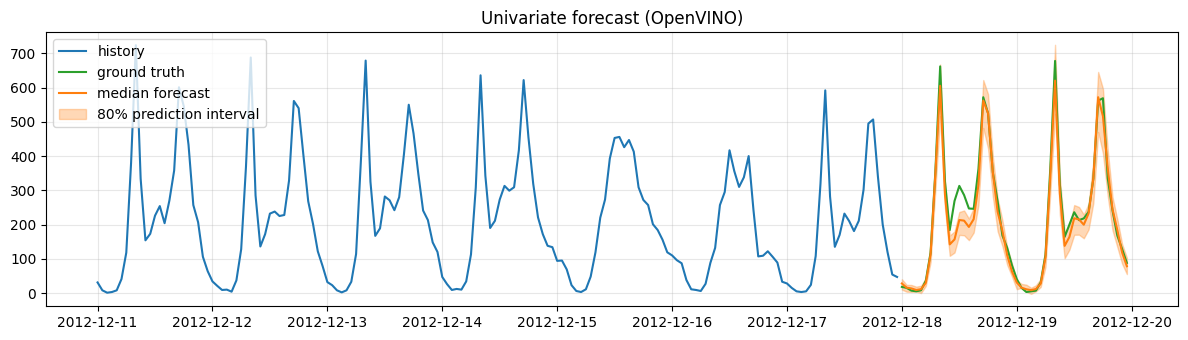

In [10]:
import numpy as np

from ov_chronos2_helper import plot_forecast

PREDICT_KWARGS = dict(
    prediction_length=PREDICTION_LENGTH,
    quantile_levels=QUANTILE_LEVELS,
    id_column=ID_COLUMN,
    timestamp_column=TIMESTAMP_COLUMN,
)


def mae(forecast_df: pd.DataFrame, ground_truth_df: pd.DataFrame, target: str) -> float:
    """
    Computes mean absolute error of the median forecast.

    :param forecast_df: data frame returned by `Chronos2Pipeline.predict_df`
    :param ground_truth_df: data frame with actual future values
    :param target: name of the forecasted column
    :returns: mean absolute error
    """
    predictions = forecast_df.loc[forecast_df["target_name"] == target, "0.5"].to_numpy()
    return float(np.abs(predictions - ground_truth_df[target].to_numpy()).mean())


start = time.perf_counter()
ov_forecast_df = ov_pipeline.predict_df(context_df[[ID_COLUMN, TIMESTAMP_COLUMN, TARGET]], target=TARGET, **PREDICT_KWARGS)
print(f"OpenVINO forecast time: {time.perf_counter() - start:.2f} s")

print(f"PyTorch MAE: {mae(torch_forecast_df, future_df, TARGET):.2f}")
print(f"OpenVINO ({ov_model_dir.name}) MAE: {mae(ov_forecast_df, future_df, TARGET):.2f}")

plot_forecast(context_df, ov_forecast_df, target=TARGET, ground_truth_df=future_df, title="Univariate forecast (OpenVINO)");

### Forecasting with known future covariates
[back to top ⬆️](#Table-of-contents:)

Weather and calendar strongly affect bike rentals. With Chronos-2, we can simply add them as extra columns. Columns that are present in both the history `df` and `future_df` are treated as *known future covariates*, and columns present only in `df` are treated as *past-only covariates*. The model sees covariates as additional series in the same group and learns their relation to the target in-context, without any training.

> **Note**: for demonstration purposes, observed weather is used as the "future" covariate. In a real application, it would be replaced by a weather forecast.

OpenVINO forecast time: 2.62 s
MAE without covariates: 22.28
MAE with covariates:    16.51


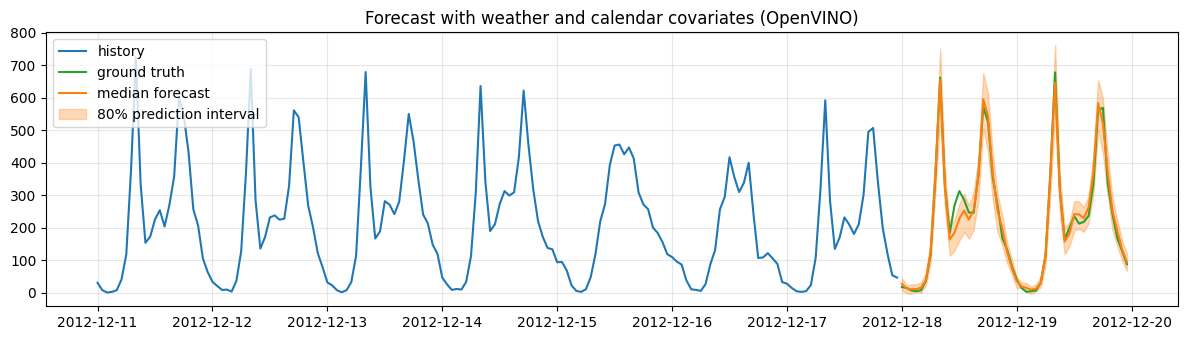

In [11]:
start = time.perf_counter()
ov_cov_forecast_df = ov_pipeline.predict_df(
    context_df[[ID_COLUMN, TIMESTAMP_COLUMN, TARGET] + COVARIATES],
    future_df=future_df[[ID_COLUMN, TIMESTAMP_COLUMN] + COVARIATES],
    target=TARGET,
    **PREDICT_KWARGS,
)
print(f"OpenVINO forecast time: {time.perf_counter() - start:.2f} s")

print(f"MAE without covariates: {mae(ov_forecast_df, future_df, TARGET):.2f}")
print(f"MAE with covariates:    {mae(ov_cov_forecast_df, future_df, TARGET):.2f}")

plot_forecast(context_df, ov_cov_forecast_df, target=TARGET, ground_truth_df=future_df, title="Forecast with weather and calendar covariates (OpenVINO)");

### Multivariate forecasting
[back to top ⬆️](#Table-of-contents:)

When several related series should be forecasted jointly, they can be passed as a list of targets. Here we forecast the rentals of `casual` and `registered` users together: the model exchanges information between them through group attention.

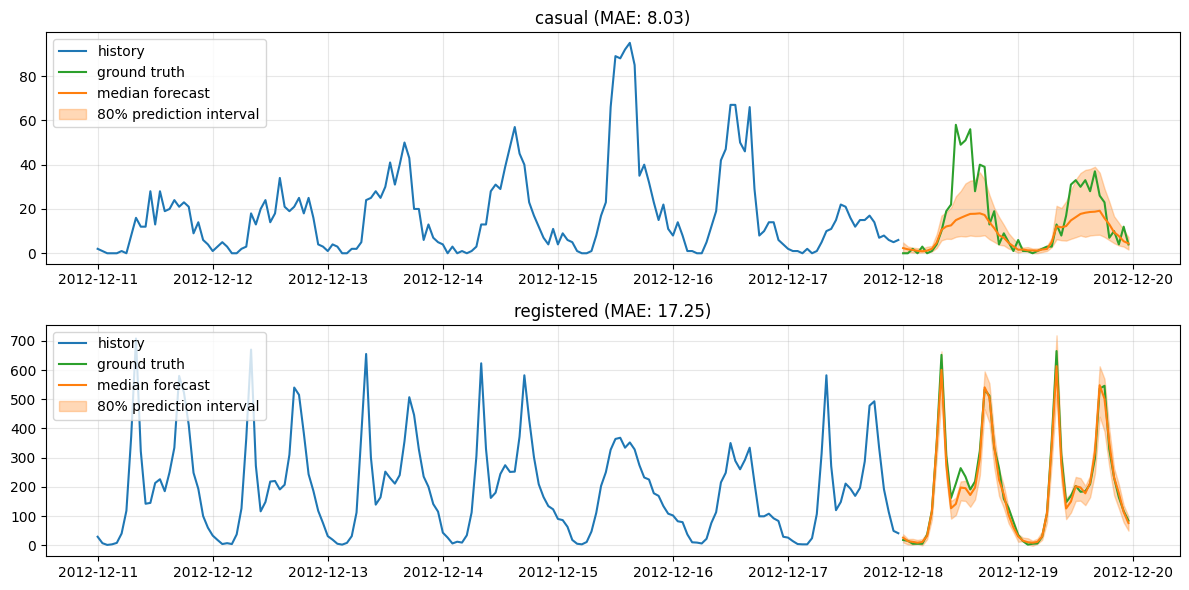

In [12]:
multivariate_targets = ["casual", "registered"]
ov_mv_forecast_df = ov_pipeline.predict_df(context_df[[ID_COLUMN, TIMESTAMP_COLUMN] + multivariate_targets], target=multivariate_targets, **PREDICT_KWARGS)

fig, axes = plt.subplots(2, 1, figsize=(12, 6))
for ax, target in zip(axes, multivariate_targets):
    plot_forecast(
        context_df, ov_mv_forecast_df, target=target, ground_truth_df=future_df, title=f"{target} (MAE: {mae(ov_mv_forecast_df, future_df, target):.2f})", ax=ax
    )

## Compare accuracy and performance
[back to top ⬆️](#Table-of-contents:)

To get a more reliable estimate than a single forecast, we run a rolling *backtest*: several forecast windows with different cut-off points from the last weeks of the dataset are predicted in one batch with covariates. We compare the mean absolute error and the time of `predict_df` call for the original PyTorch model and OpenVINO models with FP16 and INT8 weights. The first call is used for warm-up.

> **Note**: performance numbers depend on the hardware. Weight compression mostly helps on memory-bound workloads (small batches and short contexts), while large batches are compute-bound.

In [13]:
NUM_WINDOWS = 12
BACKTEST_CONTEXT_LENGTH = 1024
BACKTEST_HORIZON = 24

backtest_context, backtest_future = [], []
for i in range(NUM_WINDOWS):
    cutoff = len(data) - BACKTEST_HORIZON - 24 * (NUM_WINDOWS - i)
    window_context = data.iloc[cutoff - BACKTEST_CONTEXT_LENGTH : cutoff].assign(**{ID_COLUMN: f"window_{i}"})
    window_future = data.iloc[cutoff : cutoff + BACKTEST_HORIZON].assign(**{ID_COLUMN: f"window_{i}"})
    backtest_context.append(window_context)
    backtest_future.append(window_future)
backtest_context = pd.concat(backtest_context)[[ID_COLUMN, TIMESTAMP_COLUMN, TARGET] + COVARIATES]
backtest_future = pd.concat(backtest_future)


def run_backtest(pipeline: Chronos2Pipeline, num_runs: int = 3) -> tuple:
    """
    Runs rolling backtest with covariates and measures prediction time.

    :param pipeline: Chronos2Pipeline with PyTorch or OpenVINO model
    :param num_runs: number of measured runs
    :returns: mean absolute error and average prediction time in seconds
    """
    kwargs = dict(
        future_df=backtest_future[[ID_COLUMN, TIMESTAMP_COLUMN] + COVARIATES],
        prediction_length=BACKTEST_HORIZON,
        quantile_levels=QUANTILE_LEVELS,
        id_column=ID_COLUMN,
        timestamp_column=TIMESTAMP_COLUMN,
        target=TARGET,
    )
    forecast = pipeline.predict_df(backtest_context, **kwargs)
    start = time.perf_counter()
    for _ in range(num_runs):
        forecast = pipeline.predict_df(backtest_context, **kwargs)
    elapsed = (time.perf_counter() - start) / num_runs
    error = np.abs(forecast["0.5"].to_numpy() - backtest_future[TARGET].to_numpy()).mean()
    return error, elapsed


candidates = {"PyTorch (FP32)": torch_pipeline, f"OpenVINO FP16 weights ({device.value})": load_ov_chronos2_pipeline(FP_MODEL_DIR, device=device.value)}
if to_compress.value:
    candidates[f"OpenVINO INT8 weights ({device.value})"] = ov_pipeline

results = []
for name, pipeline in candidates.items():
    error, elapsed = run_backtest(pipeline)
    results.append({"model": name, "MAE": round(error, 2), "time, s": round(elapsed, 2)})
pd.DataFrame(results).set_index("model")

,MAE,"time, s"
model,,
PyTorch (FP32),36.74,4.65
OpenVINO FP16 weights (CPU),36.75,3.91
OpenVINO INT8 weights (CPU),36.53,3.83


## Interactive demo
[back to top ⬆️](#Table-of-contents:)

Now you can try the forecasting interactively: select a forecast start point, the length of history passed to the model and the forecast horizon, and enable or disable covariates.

In [ ]:
from gradio_helper import make_demo

demo = make_demo(ov_pipeline, data, target=TARGET, covariates=COVARIATES, id_column=ID_COLUMN, timestamp_column=TIMESTAMP_COLUMN)

# if you are launching remotely, specify server_name and server_port
# demo.launch(server_name='your server name', server_port='server port in int')
# Read more in the docs: https://gradio.app/docs/
demo.launch(debug=True)

In [14]:
# please uncomment and run this cell for stopping gradio interface
# demo.close()

## Clean up
[back to top ⬆️](#Table-of-contents:)

Uncomment and run the cell below to remove the downloaded dataset and converted models.

In [15]:
# shutil.rmtree(DATA_DIR, ignore_errors=True)
# shutil.rmtree(MODEL_DIR, ignore_errors=True)